In [1]:
%pip install -U transformers accelerate safetensors

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 35.7 MB/s eta 0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.18.0
    Uninstalling transformers-5.18.0:
      Successfully uninstalled transformers-5.18.0


In [2]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, Qwen3_5ForConditionalGeneration

MODEL_ID = "Qwen/Qwen3.5-4B-Base"
# Para usar a versão ajustada para instruções: "Qwen/Qwen3.5-4B".


def carregar_qwen(model_id=MODEL_ID):
    if torch.cuda.is_available():
        dtype = (
            torch.bfloat16
            if torch.cuda.is_bf16_supported()
            else torch.float16
        )
    else:
        dtype = torch.float32

    tokenizer = AutoTokenizer.from_pretrained(model_id)

    model = Qwen3_5ForConditionalGeneration.from_pretrained(
        model_id,
        dtype=dtype,
        device_map="auto",
        attn_implementation="sdpa",
    )

    model.eval()
    return model, tokenizer


def analisar_previsoes(text, model, tokenizer, top_k=5):
    model.eval()

    inputs = tokenizer(
        text,
        return_tensors="pt",
        add_special_tokens=False,
    )
    tokens = inputs["input_ids"][0]

    if tokens.numel() < 2:
        raise ValueError("O texto precisa conter pelo menos dois tokens.")

    device = model.get_input_embeddings().weight.device
    inputs = inputs.to(device)

    with torch.inference_mode():
        outputs = model(
            **inputs,
            use_cache=False,
            logits_to_keep=0,  # Logits de todas as posições.
        )

        # A última posição não tem próximo token observado no texto.
        # Calcula as perdas na CPU, em float32.
        logits = outputs.logits[0, :-1, :].to(
            device="cpu",
            dtype=torch.float32,
        )

    del outputs

    tokens = tokens.cpu()
    targets = tokens[1:]

    logits_log_sm = F.log_softmax(logits, dim=-1)
    losses = F.nll_loss(
        logits_log_sm,
        targets,
        reduction="none",
    )

    # As probabilidades consideram todo o vocabulário.
    top_logits, top_ids = logits.topk(k=top_k, dim=-1)
    top_probs = logits_log_sm.gather(1, top_ids).exp()

    losses_acumuladas = losses.cumsum(dim=0)
    medias_acumuladas = losses_acumuladas / torch.arange(
        1, losses.numel() + 1
    )

    token_ids = tokens.tolist()

    print(f"Tokens: {tokens.numel()} | Únicos: {tokens.unique().numel()}")

    for i in range(losses.numel()):
        target_id = targets[i].item()

        target_token = tokenizer.decode(
            [target_id],
            clean_up_tokenization_spaces=False,
        )
        contexto = tokenizer.decode(
            token_ids[:i + 1],
            clean_up_tokenization_spaces=False,
        )

        prob_correto = logits_log_sm[i, target_id].exp().item()

        print("\n" + "=" * 78)
        print(f"Previsão {i + 1}/{losses.numel()}")
        print(f"Contexto: {contexto!r}")
        print(f"Token correto: {target_token!r} | ID: {target_id}")
        print(f"Logit do correto: {logits[i, target_id].item():.4f}")
        print(f"Probabilidade do correto: {prob_correto:.6%}")
        print(f"Perda nesta previsão: {losses[i].item():.6f}")
        print(f"Soma acumulada: {losses_acumuladas[i].item():.6f}")
        print(f"Perda média até aqui: {medias_acumuladas[i].item():.6f}")

        print(f"\nTop {top_k} tokens:")
        print(
            f"{'Pos.':>4} {'ID':>6} {'Token':<18} "
            f"{'Logit':>11} {'Probabilidade':>16}"
        )

        for j in range(top_k):
            tid = top_ids[i, j].item()
            token = tokenizer.decode(
                [tid],
                clean_up_tokenization_spaces=False,
            )
            marca = " <- correto" if tid == target_id else ""

            print(
                f"{j + 1:>4} {tid:>6} {token!r:<18} "
                f"{top_logits[i, j].item():>11.4f} "
                f"{top_probs[i, j].item():>16.6%}{marca}"
            )

    loss = losses.mean().item()
    loss_total = losses.sum().item()

    print("\n" + "=" * 78)
    print(f"Soma total das perdas: {loss_total:.6f}")
    print(f"Perda média final: {loss:.6f}")

    return {
        "loss": loss,
        "loss_total": loss_total,
        "losses": losses,
        "losses_acumuladas": losses_acumuladas,
        "medias_acumuladas": medias_acumuladas,
    }


model, tokenizer = carregar_qwen()

text = (
    "There are places I remember all my life, though some have changed. "
    "Some forever, not for better, some have gone and some remain."
)

resultados = analisar_previsoes(text, model, tokenizer)

config.json:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 12.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors.index.json:   0%|          | 0.00/76.2k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


Tokens: 28 | Únicos: 22

Previsão 1/27
Contexto: 'There'
Token correto: ' are' | ID: 513
Logit do correto: 19.4199
Probabilidade do correto: 54.456550%
Perda nesta previsão: 0.607767
Soma acumulada: 0.607767
Perda média até aqui: 0.607767

Top 5 tokens:
Pos.     ID Token                    Logit    Probabilidade
   1    513 ' are'                 19.4199       54.456550% <- correto
   2    369 ' is'                  18.6513       25.249502%
   3    579 "'s"                   16.9943        4.815176%
   4    557 ' was'                 16.4368        2.757302%
   5    998 ' were'                16.0911        1.951408%

Previsão 2/27
Contexto: 'There are'
Token correto: ' places' | ID: 7247
Logit do correto: 11.4605
Probabilidade do correto: 0.017866%
Perda nesta previsão: 8.629999
Soma acumulada: 9.237766
Perda média até aqui: 4.618883

Top 5 tokens:
Pos.     ID Token                    Logit    Probabilidade
   1    220 ' '                    18.6206       22.995791%
   2   1330 ' two'

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import torch

In [ ]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':300,
})

# **Part 1: Embeddings from two LLMs**

In [ ]:
# BERT tokenizer and model
from transformers import BertTokenizer, BertModel

# load BERT tokenizer and model
tokenizerB = BertTokenizer.from_pretrained('bert-large-uncased')
modelB = BertModel.from_pretrained('bert-large-uncased')

# the embeddings matrix
embeddingsB = modelB.embeddings.word_embeddings.weight.detach()

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-large-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
# GPT2 tokenizer and model
from transformers import AutoTokenizer,GPT2Model
tokenizerG = AutoTokenizer.from_pretrained('gpt2-medium')
modelG = GPT2Model.from_pretrained('gpt2-medium')

# the embeddings matrix
embeddingsG = modelG.wte.weight.detach()

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

In [ ]:
print(f'BERT vocabulary size: {tokenizerB.vocab_size}')
print(f'GPT2 vocabulary size: {tokenizerG.vocab_size}')
print('')

print(f'BERT embeddings shape: {list(embeddingsB.shape)}')
print(f'GPT2 embeddings shape: {list(embeddingsG.shape)}')

BERT vocabulary size: 30522
GPT2 vocabulary size: 50257

BERT embeddings shape: [30522, 1024]
GPT2 embeddings shape: [50257, 1024]


# **Part 2: Comparing model embeddings**

In [ ]:
# list of words for RSA
words = [ 'space','spaceship','planet','moon'  ,'star' ,'galaxy',
          'chair','table'    ,'couch' ,'stool' ,'floor','desk',
          'apple','banana'   ,'pear'  ,'orange','peach','grape'
        ]

# will be convenient later
num_words = len(words)

# initialize lists of tokens
tokensB = []
tokensG = []

# table header
print('     Word  | B-n | G-n | B-s | G-s')
print('-----------+-----+-----+-----+-----')

for w in words:

  # tokenize without preceding spaces
  tb_nospace = tokenizerB.encode(w,add_special_tokens=False)
  tg_nospace = tokenizerG.encode(w)

  # tokenize with preceding spaces
  tb_withspace = tokenizerB.encode(f' {w}',add_special_tokens=False)
  tg_withspace = tokenizerG.encode(f' {w}')

  # print a row of the table
  print(f'{w:>10} |  {len(tb_nospace)}  |  {len(tg_nospace)}  |  {len(tb_withspace)}  |  {len(tg_withspace)}')

  # add to list
  tokensB.append(tb_nospace[0])
  tokensG.append(tg_withspace[0])

     Word  | B-n | G-n | B-s | G-s
-----------+-----+-----+-----+-----
     space |  1  |  1  |  1  |  1
 spaceship |  1  |  3  |  1  |  1
    planet |  1  |  1  |  1  |  1
      moon |  1  |  1  |  1  |  1
      star |  1  |  1  |  1  |  1
    galaxy |  1  |  2  |  1  |  1
     chair |  1  |  1  |  1  |  1
     table |  1  |  1  |  1  |  1
     couch |  1  |  2  |  1  |  1
     stool |  1  |  2  |  1  |  1
     floor |  1  |  1  |  1  |  1
      desk |  1  |  2  |  1  |  1
     apple |  1  |  1  |  1  |  1
    banana |  1  |  2  |  1  |  1
      pear |  1  |  2  |  1  |  1
    orange |  1  |  1  |  1  |  1
     peach |  1  |  2  |  1  |  1
     grape |  1  |  2  |  1  |  1


In [ ]:
tokensB,tokensG

([2686,
  25516,
  4774,
  4231,
  2732,
  9088,
  3242,
  2795,
  6411,
  14708,
  2723,
  4624,
  6207,
  15212,
  28253,
  4589,
  18237,
  14722],
 [2272,
  40663,
  5440,
  8824,
  3491,
  16161,
  5118,
  3084,
  18507,
  38753,
  4314,
  6915,
  17180,
  25996,
  25286,
  10912,
  47565,
  30777])

In [ ]:
# embeddings matrix for these words
sub_embedB = embeddingsB[tokensB,:]
sub_embedG = embeddingsG[tokensG,:]

print(f'BERT embeddings shape: {list(sub_embedB.shape)}')
print(f'GPT2 embeddings shape: {list(sub_embedG.shape)}')

BERT embeddings shape: [18, 1024]
GPT2 embeddings shape: [18, 1024]


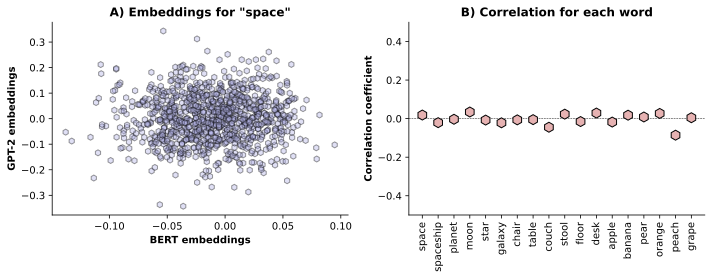

In [ ]:
_,axs = plt.subplots(1,2,figsize=(10,4))

# scatter plot of an example word
axs[0].plot(sub_embedB[0,:],sub_embedG[0,:],'kh',
            markerfacecolor=[.7,.7,.9,.4])
axs[0].set(xlabel='BERT embeddings',ylabel='GPT-2 embeddings',title=f'A) Embeddings for "{words[0]}"')

# correlations for all words
for i in range(num_words):
  r = np.corrcoef(sub_embedB[i,:],sub_embedG[i,:])[0,1]
  axs[1].plot(i,r,'kh',markerfacecolor=[.9,.7,.7],markersize=10)

axs[1].axhline(0,linestyle='--',color='k',linewidth=.5,zorder=-1)
axs[1].set(xticks=range(num_words),xticklabels=words,ylim=[-.5,.5],
           title='B) Correlation for each word',ylabel='Correlation coefficient')
axs[1].tick_params(axis='x',labelrotation=90)

plt.tight_layout()
plt.savefig('ch3_proj12_part2.png')
plt.show()

--- Exploração


In [ ]:
import pandas as pd
import numpy as np

correlation_rows = []

for i, word in enumerate(words):

    bert_vector = np.asarray(sub_embedB[i, :])
    gpt_vector = np.asarray(sub_embedG[i, :])

    correlation = np.corrcoef(
        bert_vector,
        gpt_vector
    )[0, 1]

    correlation_rows.append({
        'Word': word,
        'BERT dimensions': len(bert_vector),
        'GPT-2 dimensions': len(gpt_vector),
        'Correlation': correlation,
        'Absolute correlation': abs(correlation)
    })

correlation_table = pd.DataFrame(
    correlation_rows
)

display(
    correlation_table.style
    .background_gradient(
        subset=['Correlation'],
        cmap='coolwarm',
        vmin=-0.5,
        vmax=0.5
    )
    .format({
        'Correlation': '{:.4f}',
        'Absolute correlation': '{:.4f}'
    })
)

,Word,BERT dimensions,GPT-2 dimensions,Correlation,Absolute correlation
0,space,1024,1024,0.0186,0.0186
1,spaceship,1024,1024,-0.0209,0.0209
2,planet,1024,1024,-0.0034,0.0034
3,moon,1024,1024,0.0343,0.0343
4,star,1024,1024,-0.0076,0.0076
5,galaxy,1024,1024,-0.0217,0.0217
6,chair,1024,1024,-0.0064,0.0064
7,table,1024,1024,-0.0053,0.0053
8,couch,1024,1024,-0.0447,0.0447
9,stool,1024,1024,0.0232,0.0232


In [ ]:
print('\nTokens usados nas matrizes')
print('---------------------------------------------')

for word, tokenB, tokenG in zip(
    words,
    tokensB,
    tokensG
):

    print(
        f'{word:10} | '
        f'BERT: {tokenizerB.decode([tokenB])!r:15} | '
        f'GPT-2: {tokenizerG.decode([tokenG])!r}'
    )


Tokens usados nas matrizes
---------------------------------------------
space      | BERT: 'space'         | GPT-2: ' space'
spaceship  | BERT: 'spaceship'     | GPT-2: ' spaceship'
planet     | BERT: 'planet'        | GPT-2: ' planet'
moon       | BERT: 'moon'          | GPT-2: ' moon'
star       | BERT: 'star'          | GPT-2: ' star'
galaxy     | BERT: 'galaxy'        | GPT-2: ' galaxy'
chair      | BERT: 'chair'         | GPT-2: ' chair'
table      | BERT: 'table'         | GPT-2: ' table'
couch      | BERT: 'couch'         | GPT-2: ' couch'
stool      | BERT: 'stool'         | GPT-2: ' stool'
floor      | BERT: 'floor'         | GPT-2: ' floor'
desk       | BERT: 'desk'          | GPT-2: ' desk'
apple      | BERT: 'apple'         | GPT-2: ' apple'
banana     | BERT: 'banana'        | GPT-2: ' banana'
pear       | BERT: 'pear'          | GPT-2: ' pear'
orange     | BERT: 'orange'        | GPT-2: ' orange'
peach      | BERT: 'peach'         | GPT-2: ' peach'
grape      | BERT: 'g

In [ ]:
tokensB_all = []
tokensG_all = []

for word in words:

    tokensB_word = tokenizerB.encode(
        word,
        add_special_tokens=False
    )

    tokensG_word = tokenizerG.encode(
        word,
        add_special_tokens=False
    )

    # Adiciona todos os tokens, não apenas [0]
    tokensB_all.extend(tokensB_word)
    tokensG_all.extend(tokensG_word)


sub_embedB_all = embeddingsB[tokensB_all, :]
sub_embedG_all = embeddingsG[tokensG_all, :]

print(
    'Total de tokens BERT:',
    len(tokensB_all)
)

print(
    'Total de tokens GPT-2:',
    len(tokensG_all)
)

print(
    'BERT embeddings shape:',
    list(sub_embedB_all.shape)
)

print(
    'GPT-2 embeddings shape:',
    list(sub_embedG_all.shape)
)

Total de tokens BERT: 18
Total de tokens GPT-2: 28
BERT embeddings shape: [18, 1024]
GPT-2 embeddings shape: [28, 1024]


In [ ]:
import pandas as pd

def format_tokens(token_list, show_space=False):
    formatted = []

    for token in token_list:

        # No GPT-2, Ġ representa um espaço anterior
        if show_space:
            token = token.replace('Ġ', '␠')

        formatted.append(f'[{token}]')

    return ''.join(formatted)


tokenization_rows = []

for word in words:

    # BERT sem espaço
    bert_tokens = tokenizerB.tokenize(word)

    # GPT-2 sem espaço
    gpt_no_space = tokenizerG.tokenize(word)

    # GPT-2 com espaço inicial
    gpt_with_space = tokenizerG.tokenize(
        ' ' + word
    )

    tokenization_rows.append({
        'Word': word,
        'BERT': format_tokens(bert_tokens),
        'GPT-2 without space': format_tokens(
            gpt_no_space,
            show_space=True
        ),
        'GPT-2 with space': format_tokens(
            gpt_with_space,
            show_space=True
        ),
        'BERT count': len(bert_tokens),
        'GPT no-space count': len(gpt_no_space),
        'GPT with-space count': len(gpt_with_space)
    })

tokenization_table = pd.DataFrame(
    tokenization_rows
)

display(tokenization_table)

,Word,BERT,GPT-2 without space,GPT-2 with space,BERT count,GPT no-space count,GPT with-space count
0,space,[space],[space],[␠space],1,1,1
1,spaceship,[spaceship],[sp][aces][hip],[␠spaceship],1,3,1
2,planet,[planet],[planet],[␠planet],1,1,1
3,moon,[moon],[moon],[␠moon],1,1,1
4,star,[star],[star],[␠star],1,1,1
5,galaxy,[galaxy],[gal][axy],[␠galaxy],1,2,1
6,chair,[chair],[chair],[␠chair],1,1,1
7,table,[table],[table],[␠table],1,1,1
8,couch,[couch],[c][ouch],[␠couch],1,2,1
9,stool,[stool],[st][ool],[␠stool],1,2,1


In [ ]:
import numpy as np
import pandas as pd


def to_numpy(values):
    """Converte Tensor ou array para NumPy."""

    if hasattr(values, 'detach'):
        return values.detach().cpu().numpy()

    return np.asarray(values)


def word_embedding(
    word,
    tokenizer,
    embeddings,
    preceding_space=False
):
    """Cria um vetor por palavra pela média dos tokens."""

    text = f' {word}' if preceding_space else word

    token_ids = tokenizer.encode(
        text,
        add_special_tokens=False
    )

    token_vectors = to_numpy(
        embeddings[token_ids, :]
    )

    mean_vector = token_vectors.mean(axis=0)

    token_names = tokenizer.convert_ids_to_tokens(
        token_ids
    )

    return mean_vector, token_ids, token_names


def cosine_similarity(vector1, vector2):

    return np.dot(vector1, vector2) / (
        np.linalg.norm(vector1)
        * np.linalg.norm(vector2)
    )

In [ ]:
comparison_rows = []

for word in words:

    # BERT sem e com espaço
    bert_no_space, bert_ids_n, bert_tokens_n = (
        word_embedding(
            word,
            tokenizerB,
            embeddingsB,
            preceding_space=False
        )
    )

    bert_with_space, bert_ids_s, bert_tokens_s = (
        word_embedding(
            word,
            tokenizerB,
            embeddingsB,
            preceding_space=True
        )
    )

    # GPT-2 sem e com espaço
    gpt_no_space, gpt_ids_n, gpt_tokens_n = (
        word_embedding(
            word,
            tokenizerG,
            embeddingsG,
            preceding_space=False
        )
    )

    gpt_with_space, gpt_ids_s, gpt_tokens_s = (
        word_embedding(
            word,
            tokenizerG,
            embeddingsG,
            preceding_space=True
        )
    )

    # Correlação dentro de cada modelo
    bert_correlation = np.corrcoef(
        bert_no_space,
        bert_with_space
    )[0, 1]

    gpt_correlation = np.corrcoef(
        gpt_no_space,
        gpt_with_space
    )[0, 1]

    # Similaridade de cosseno
    bert_cosine = cosine_similarity(
        bert_no_space,
        bert_with_space
    )

    gpt_cosine = cosine_similarity(
        gpt_no_space,
        gpt_with_space
    )

    comparison_rows.append({
        'Word': word,

        'BERT no-space tokens':
            ''.join(f'[{t}]' for t in bert_tokens_n),

        'BERT with-space tokens':
            ''.join(f'[{t}]' for t in bert_tokens_s),

        'BERT correlation':
            bert_correlation,

        'BERT cosine':
            bert_cosine,

        'GPT no-space tokens':
            ''.join(
                f'[{t.replace("Ġ", "␠")}]'
                for t in gpt_tokens_n
            ),

        'GPT with-space tokens':
            ''.join(
                f'[{t.replace("Ġ", "␠")}]'
                for t in gpt_tokens_s
            ),

        'GPT correlation':
            gpt_correlation,

        'GPT cosine':
            gpt_cosine
    })

In [ ]:
comparison_rows = []

for word in words:

    # BERT sem e com espaço
    bert_no_space, bert_ids_n, bert_tokens_n = (
        word_embedding(
            word,
            tokenizerB,
            embeddingsB,
            preceding_space=False
        )
    )

    bert_with_space, bert_ids_s, bert_tokens_s = (
        word_embedding(
            word,
            tokenizerB,
            embeddingsB,
            preceding_space=True
        )
    )

    # GPT-2 sem e com espaço
    gpt_no_space, gpt_ids_n, gpt_tokens_n = (
        word_embedding(
            word,
            tokenizerG,
            embeddingsG,
            preceding_space=False
        )
    )

    gpt_with_space, gpt_ids_s, gpt_tokens_s = (
        word_embedding(
            word,
            tokenizerG,
            embeddingsG,
            preceding_space=True
        )
    )

    # Correlação dentro de cada modelo
    bert_correlation = np.corrcoef(
        bert_no_space,
        bert_with_space
    )[0, 1]

    gpt_correlation = np.corrcoef(
        gpt_no_space,
        gpt_with_space
    )[0, 1]

    # Similaridade de cosseno
    bert_cosine = cosine_similarity(
        bert_no_space,
        bert_with_space
    )

    gpt_cosine = cosine_similarity(
        gpt_no_space,
        gpt_with_space
    )

    comparison_rows.append({
        'Word': word,

        'BERT no-space tokens':
            ''.join(f'[{t}]' for t in bert_tokens_n),

        'BERT with-space tokens':
            ''.join(f'[{t}]' for t in bert_tokens_s),

        'BERT correlation':
            bert_correlation,

        'BERT cosine':
            bert_cosine,

        'GPT no-space tokens':
            ''.join(
                f'[{t.replace("Ġ", "␠")}]'
                for t in gpt_tokens_n
            ),

        'GPT with-space tokens':
            ''.join(
                f'[{t.replace("Ġ", "␠")}]'
                for t in gpt_tokens_s
            ),

        'GPT correlation':
            gpt_correlation,

        'GPT cosine':
            gpt_cosine
    })

In [ ]:
space_comparison = pd.DataFrame(
    comparison_rows
)

display(
    space_comparison.style
    .background_gradient(
        subset=[
            'BERT cosine',
            'GPT cosine'
        ],
        cmap='viridis',
        vmin=-1,
        vmax=1
    )
    .format({
        'BERT correlation': '{:.4f}',
        'BERT cosine': '{:.4f}',
        'GPT correlation': '{:.4f}',
        'GPT cosine': '{:.4f}'
    })
)

,Word,BERT no-space tokens,BERT with-space tokens,BERT correlation,BERT cosine,GPT no-space tokens,GPT with-space tokens,GPT correlation,GPT cosine
0,space,[space],[space],1.0000,1.0000,[space],[␠space],0.7298,0.7298
1,spaceship,[spaceship],[spaceship],1.0000,1.0000,[sp][aces][hip],[␠spaceship],0.4600,0.4594
2,planet,[planet],[planet],1.0000,1.0000,[planet],[␠planet],0.7211,0.7210
3,moon,[moon],[moon],1.0000,1.0000,[moon],[␠moon],0.6765,0.6763
4,star,[star],[star],1.0000,1.0000,[star],[␠star],0.6832,0.6832
5,galaxy,[galaxy],[galaxy],1.0000,1.0000,[gal][axy],[␠galaxy],0.5353,0.5349
6,chair,[chair],[chair],1.0000,1.0000,[chair],[␠chair],0.7273,0.7272
7,table,[table],[table],1.0000,1.0000,[table],[␠table],0.7137,0.7138
8,couch,[couch],[couch],1.0000,1.0000,[c][ouch],[␠couch],0.4292,0.4292
9,stool,[stool],[stool],1.0000,1.0000,[st][ool],[␠stool],0.4479,0.4478


# **Part 3: Representational similarity analysis**

In [ ]:
# cosine similarities
csG = torch.zeros((num_words,num_words))
csB = torch.zeros((num_words,num_words))

for i in range(num_words):
  csB[i,:] = torch.cosine_similarity(sub_embedB[i],sub_embedB)
  csG[i,:] = torch.cosine_similarity(sub_embedG[i],sub_embedG)


# extract the upper-triangular elements
unique_B = csB[np.triu_indices_from(csB, k=1)]
unique_G = csG[np.triu_indices_from(csG, k=1)]

# Pearson correlation
r = np.corrcoef(unique_B,unique_G)[0,1]

print(f'Size of similarity matrices: {csB.shape}')
print(f'Number of non-redundant elements: {len(unique_B)}')

Size of similarity matrices: torch.Size([18, 18])
Number of non-redundant elements: 153


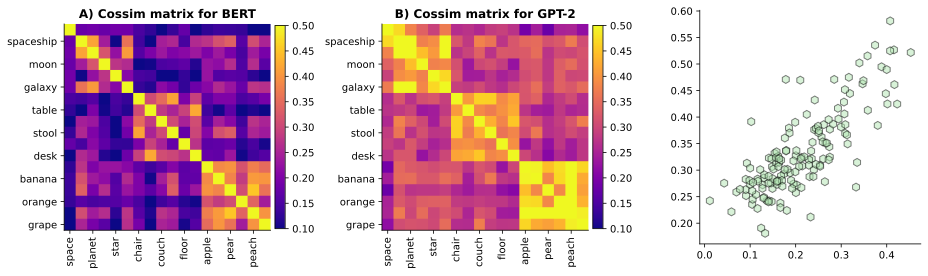

In [ ]:
# and visualize
fig,axs = plt.subplots(1,3,figsize=(13,4))

# color limits for images
vminmax = [.1,.5]

# BERT: cosine similarity matrix
h = axs[0].imshow(csB,vmin=vminmax[0],vmax=vminmax[1],cmap='plasma')
axs[0].set(xticks=range(0,len(words),2),xticklabels=words[::2],
           yticks=range(1,len(words),2),yticklabels=words[1::2],
           title='A) Cossim matrix for BERT')
axs[0].tick_params(axis='x',labelrotation=90)
fig.colorbar(h,ax=axs[0],fraction=.046,pad=.02)


# GPT2: cosine similarity matrix
h = axs[1].imshow(csG,vmin=vminmax[0],vmax=vminmax[1],cmap='plasma')
axs[1].set(xticks=range(0,len(words),2),xticklabels=words[::2],
           yticks=range(1,len(words),2),yticklabels=words[1::2],
           title='B) Cossim matrix for GPT-2')
axs[1].tick_params(axis='x',labelrotation=90)
fig.colorbar(h,ax=axs[1],fraction=.046,pad=.02)


# scatter plot
axs[2].plot(
    unique_B,
    unique_G,
    'kh',
    markersize=8,
    markerfacecolor=[.7, .9, .7, .5]
)


plt.tight_layout()
plt.savefig('ch3_proj12_part3.png')
plt.show()

BERT embeddings: (18, 1024)
GPT-2 embeddings: (18, 1024)
BERT cosine matrix: (18, 18)
GPT-2 cosine matrix: (18, 18)
Quantidade de pares únicos: 153
RSA score: r = 0.7884


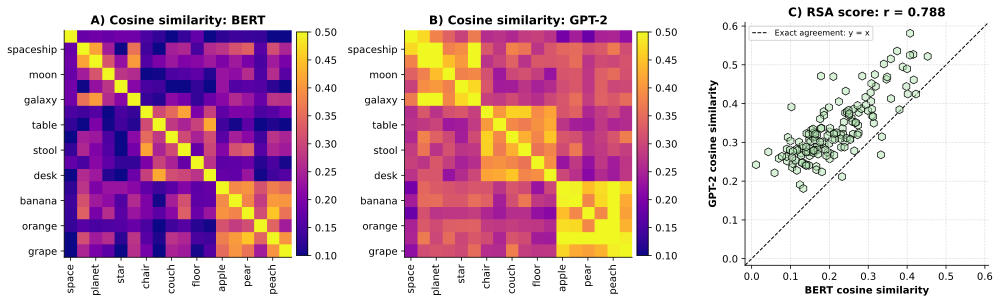

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ---------------------------------------------------------
# 1. Converter os embeddings para NumPy
# ---------------------------------------------------------

def to_numpy(values):

    if hasattr(values, 'detach'):
        return values.detach().cpu().numpy()

    return np.asarray(values)


embedB = to_numpy(sub_embedB)
embedG = to_numpy(sub_embedG)

num_words = len(words)

print('BERT embeddings:', embedB.shape)
print('GPT-2 embeddings:', embedG.shape)

assert embedB.shape[0] == num_words
assert embedG.shape[0] == num_words


# ---------------------------------------------------------
# 2. Normalizar cada embedding
# ---------------------------------------------------------

normB = np.linalg.norm(
    embedB,
    axis=1,
    keepdims=True
)

normG = np.linalg.norm(
    embedG,
    axis=1,
    keepdims=True
)

embedB_normalized = embedB / normB
embedG_normalized = embedG / normG


# ---------------------------------------------------------
# 3. Matrizes de similaridade de cosseno
# ---------------------------------------------------------

csB = (
    embedB_normalized
    @ embedB_normalized.T
)

csG = (
    embedG_normalized
    @ embedG_normalized.T
)

print('BERT cosine matrix:', csB.shape)
print('GPT-2 cosine matrix:', csG.shape)


# ---------------------------------------------------------
# 4. Selecionar somente os pares únicos
# ---------------------------------------------------------

# k=1 exclui a diagonal e seleciona somente
# a parte superior da matriz
row_indices, column_indices = np.triu_indices(
    num_words,
    k=1
)

unique_B = csB[
    row_indices,
    column_indices
]

unique_G = csG[
    row_indices,
    column_indices
]

print('Quantidade de pares únicos:', len(unique_B))

expected_pairs = (
    num_words * (num_words - 1) // 2
)

assert len(unique_B) == expected_pairs
assert len(unique_G) == expected_pairs


# ---------------------------------------------------------
# 5. Correlação RSA
# ---------------------------------------------------------

r = np.corrcoef(
    unique_B,
    unique_G
)[0, 1]

print(f'RSA score: r = {r:.4f}')


# ---------------------------------------------------------
# 6. Criar tabela correspondente ao terceiro gráfico
# ---------------------------------------------------------

rsa_rows = []

for point_number, (i, j) in enumerate(
    zip(row_indices, column_indices),
    start=1
):

    bert_similarity = csB[i, j]
    gpt_similarity = csG[i, j]

    rsa_rows.append({
        'Point': point_number,
        'Word 1': words[i],
        'Word 2': words[j],
        'Pair': f'{words[i]} × {words[j]}',
        'BERT cosine similarity': bert_similarity,
        'GPT-2 cosine similarity': gpt_similarity,
        'Difference: GPT - BERT':
            gpt_similarity - bert_similarity,
        'Absolute difference':
            abs(gpt_similarity - bert_similarity)
    })

rsa_table = pd.DataFrame(rsa_rows)


# ---------------------------------------------------------
# 7. Limites compartilhados no terceiro gráfico
# ---------------------------------------------------------

common_min = min(
    unique_B.min(),
    unique_G.min()
)

common_max = max(
    unique_B.max(),
    unique_G.max()
)

# Pequena margem visual
data_range = common_max - common_min

if data_range == 0:
    padding = 0.05
else:
    padding = data_range * 0.05

axis_min = common_min - padding
axis_max = common_max + padding


# ---------------------------------------------------------
# 8. Criar os três gráficos
# ---------------------------------------------------------

fig, axs = plt.subplots(
    1,
    3,
    figsize=(14, 4.5)
)

# Mesma escala de cores para as duas matrizes
vminmax = [0.1, 0.5]


# ---------------------------------------------------------
# Painel A: matriz BERT
# ---------------------------------------------------------

h = axs[0].imshow(
    csB,
    vmin=vminmax[0],
    vmax=vminmax[1],
    cmap='plasma'
)

axs[0].set(
    xticks=range(0, num_words, 2),
    xticklabels=words[::2],
    yticks=range(1, num_words, 2),
    yticklabels=words[1::2],
    title='A) Cosine similarity: BERT'
)

axs[0].tick_params(
    axis='x',
    labelrotation=90
)

fig.colorbar(
    h,
    ax=axs[0],
    fraction=0.046,
    pad=0.02
)


# ---------------------------------------------------------
# Painel B: matriz GPT-2
# ---------------------------------------------------------

h = axs[1].imshow(
    csG,
    vmin=vminmax[0],
    vmax=vminmax[1],
    cmap='plasma'
)

axs[1].set(
    xticks=range(0, num_words, 2),
    xticklabels=words[::2],
    yticks=range(1, num_words, 2),
    yticklabels=words[1::2],
    title='B) Cosine similarity: GPT-2'
)

axs[1].tick_params(
    axis='x',
    labelrotation=90
)

fig.colorbar(
    h,
    ax=axs[1],
    fraction=0.046,
    pad=0.02
)


# ---------------------------------------------------------
# Painel C: gráfico RSA
# ---------------------------------------------------------

axs[2].scatter(
    unique_B,
    unique_G,
    marker='h',
    s=65,
    facecolor=[0.7, 0.9, 0.7, 0.5],
    edgecolor='black',
    linewidth=0.7
)

# Reta de 45 graus: y = x
axs[2].plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    color='black',
    linestyle='--',
    linewidth=1,
    label='Exact agreement: y = x',
    zorder=-1
)

# Mesmos limites nos dois eixos
axs[2].set_xlim(
    axis_min,
    axis_max
)

axs[2].set_ylim(
    axis_min,
    axis_max
)

# Mesma escala física nos eixos
axs[2].set_aspect(
    'equal',
    adjustable='box'
)

axs[2].set(
    xlabel='BERT cosine similarity',
    ylabel='GPT-2 cosine similarity',
    title=f'C) RSA score: r = {r:.3f}'
)

axs[2].grid(
    linestyle='--',
    color=[0.85, 0.85, 0.85],
    linewidth=0.6
)

axs[2].legend(
    loc='best',
    fontsize=8
)


# ---------------------------------------------------------
# 9. Finalizar e salvar
# ---------------------------------------------------------

plt.tight_layout()

plt.savefig(
    'ch3_proj12_part3_corrected.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
display(
    rsa_table.style
    .background_gradient(
        subset=[
            'BERT cosine similarity',
            'GPT-2 cosine similarity'
        ],
        cmap='plasma',
        vmin=common_min,
        vmax=common_max
    )
    .format({
        'BERT cosine similarity': '{:.4f}',
        'GPT-2 cosine similarity': '{:.4f}',
        'Difference: GPT - BERT': '{:+.4f}',
        'Absolute difference': '{:.4f}'
    })
)

,Point,Word 1,Word 2,Pair,BERT cosine similarity,GPT-2 cosine similarity,Difference: GPT - BERT,Absolute difference
0,1,space,spaceship,space × spaceship,0.1783,0.4710,+0.2927,0.2927
1,2,space,planet,space × planet,0.1853,0.3794,+0.1941,0.1941
2,3,space,moon,space × moon,0.1794,0.3371,+0.1577,0.1577
3,4,space,star,space × star,0.1876,0.2948,+0.1073,0.1073
4,5,space,galaxy,space × galaxy,0.1865,0.3700,+0.1835,0.1835
5,6,space,chair,space × chair,0.1490,0.2654,+0.1164,0.1164
6,7,space,table,space × table,0.1274,0.2724,+0.1450,0.1450
7,8,space,couch,space × couch,0.0698,0.2586,+0.1888,0.1888
8,9,space,stool,space × stool,0.1299,0.2852,+0.1553,0.1553
9,10,space,floor,space × floor,0.1744,0.2929,+0.1185,0.1185


# **Part 4: Different embeddings sizes**

In [ ]:
def find_loaded_model(model_type):

    candidates = {}

    # list() evita alterações no dicionário durante a busca
    for name, obj in list(globals().items()):

        config = getattr(obj, "config", None)

        if (
            getattr(config, "model_type", None) == model_type
            and callable(getattr(obj, "get_input_embeddings", None))
        ):
            # Diferentes nomes podem apontar para o mesmo modelo
            candidates.setdefault(id(obj), (name, obj))

    if not candidates:
        raise ValueError(
            f"Nenhum modelo '{model_type}' encontrado. "
            "Execute antes a célula que carrega esse modelo."
        )

    if len(candidates) > 1:
        names = [name for name, _ in candidates.values()]
        raise ValueError(
            f"Há vários modelos '{model_type}': {names}. "
            "É necessário escolher qual usar."
        )

    name, model = next(iter(candidates.values()))
    print(f"Modelo {model_type} encontrado na variável: {name}")

    return model


loaded_bert = find_loaded_model("bert")
loaded_gpt2 = find_loaded_model("gpt2")

heatB, vocabB = vocabulary_cosine_heatmap(
    loaded_bert.get_input_embeddings().weight
)

heatG, vocabG = vocabulary_cosine_heatmap(
    loaded_gpt2.get_input_embeddings().weight
)

Modelo bert encontrado na variável: modelB
Modelo gpt2 encontrado na variável: modelG



BERT large
  Tokens: 30,522
  Dimensões por embedding: 1,024
  Matriz de embeddings: (30522, 1024)
  Matriz completa de cossenos em float32: 3.47 GiB
  Normas originais: mínima=0.9192, média=1.4540, máxima=2.3669
  Mapa exibido: (600, 600)
  Tokens por grupo: entre 50 e 51
  Cossenos médios dos blocos: mínimo=-0.1777, máximo=0.9482

GPT-2 medium
  Tokens: 50,257
  Dimensões por embedding: 1,024
  Matriz de embeddings: (50257, 1024)
  Matriz completa de cossenos em float32: 9.41 GiB
  Normas originais: mínima=2.0123, média=3.6842, máxima=5.7009
  Mapa exibido: (600, 600)
  Tokens por grupo: entre 83 e 84
  Cossenos médios dos blocos: mínimo=0.2531, máximo=0.6250


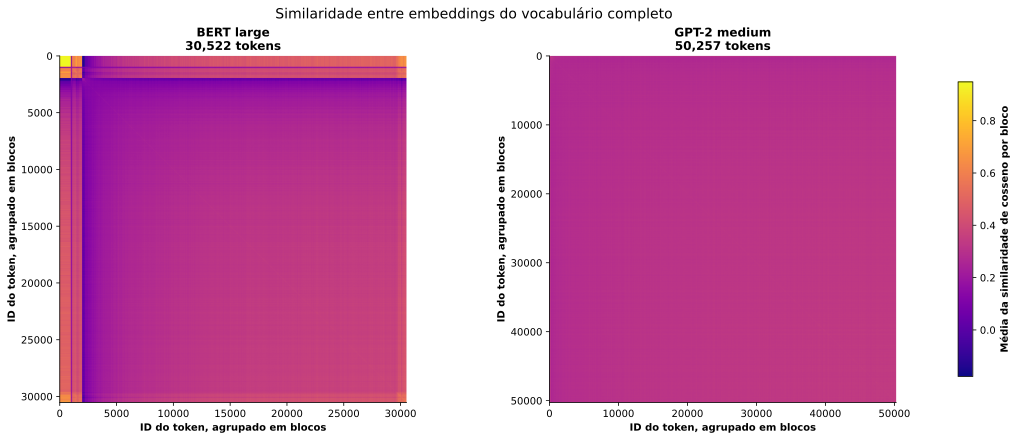

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from transformers import BertModel, GPT2Model


# =========================================================
# 1. Carregar ou reutilizar os modelos
# =========================================================

if "modelB" not in globals():
    print("Carregando bert-large-uncased...", flush=True)
    modelB = BertModel.from_pretrained("bert-large-uncased")

if "modelG" not in globals():
    print("Carregando gpt2-medium...", flush=True)
    modelG = GPT2Model.from_pretrained("gpt2-medium")

# Matrizes COMPLETAS: todos os tokens × dimensões
embeddingsB = modelB.embeddings.word_embeddings.weight.detach()
embeddingsG = modelG.wte.weight.detach()


# =========================================================
# 2. Construir o mapa usando todos os embeddings
# =========================================================

def build_cosine_heatmap(embeddings, model_name, num_blocks=600):

    E = embeddings.cpu().float().numpy().copy()

    num_tokens, num_dimensions = E.shape

    print(f"\n{model_name}", flush=True)
    print(f"  Tokens: {num_tokens:,}")
    print(f"  Dimensões por embedding: {num_dimensions:,}")
    print(f"  Matriz de embeddings: {E.shape}")

    full_matrix_gib = num_tokens**2 * 4 / 1024**3

    print(
        f"  Matriz completa de cossenos em float32: "
        f"{full_matrix_gib:.2f} GiB"
    )

    # Cada linha corresponde a um embedding
    norms = np.linalg.norm(E, axis=1, keepdims=True)

    if not np.isfinite(E).all():
        raise ValueError(f"{model_name}: há valores NaN ou infinitos.")

    zero_ids = np.flatnonzero(norms[:, 0] == 0)

    if zero_ids.size:
        raise ValueError(
            f"{model_name}: cosseno indefinido para embeddings "
            f"com norma zero. IDs: {zero_ids[:20].tolist()}"
        )

    print(
        f"  Normas originais: "
        f"mínima={norms.min():.4f}, "
        f"média={norms.mean():.4f}, "
        f"máxima={norms.max():.4f}"
    )

    # Normalizar TODOS os embeddings individualmente
    E /= norms

    # Grupos consecutivos de IDs, cobrindo todo o vocabulário
    num_blocks = min(num_blocks, num_tokens)

    boundaries = np.linspace(
        0,
        num_tokens,
        num_blocks + 1,
        dtype=int
    )

    counts = np.diff(boundaries)

    # Média dos embeddings normalizados em cada grupo
    group_means = np.add.reduceat(
        E,
        boundaries[:-1],
        axis=0
    )

    group_means /= counts[:, None]

    # Produto das médias = média dos cossenos entre os grupos.
    # NÃO normalizar novamente group_means.
    heatmap = group_means @ group_means.T

    print(f"  Mapa exibido: {heatmap.shape}")
    print(
        f"  Tokens por grupo: "
        f"entre {counts.min()} e {counts.max()}"
    )
    print(
        f"  Cossenos médios dos blocos: "
        f"mínimo={heatmap.min():.4f}, "
        f"máximo={heatmap.max():.4f}",
        flush=True
    )

    return heatmap, num_tokens


# Aumente para obter mais detalhes visuais
NUM_BLOCKS = 600

heatB, vocabB = build_cosine_heatmap(
    embeddingsB,
    "BERT large",
    num_blocks=NUM_BLOCKS
)

heatG, vocabG = build_cosine_heatmap(
    embeddingsG,
    "GPT-2 medium",
    num_blocks=NUM_BLOCKS
)


# =========================================================
# 3. Definir uma escala de cores compartilhada
# =========================================================

# Limites obtidos dos DOIS mapas, para aumentar o contraste
# sem perder a comparabilidade das cores
vmin = min(float(heatB.min()), float(heatG.min()))
vmax = max(float(heatB.max()), float(heatG.max()))

if vmin == vmax:
    vmin -= 0.01
    vmax += 0.01

# Para usar a faixa teórica completa do cosseno:
# vmin, vmax = -1, 1


# =========================================================
# 4. Exibir os dois gráficos
# =========================================================

fig, axs = plt.subplots(
    1,
    2,
    figsize=(15, 6),
    constrained_layout=True
)

for ax, heatmap, vocab_size, model_name in zip(
    axs,
    [heatB, heatG],
    [vocabB, vocabG],
    ["BERT large", "GPT-2 medium"]
):

    h = ax.imshow(
        heatmap,
        cmap="plasma",
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
        extent=(
            -0.5, vocab_size - 0.5,
            vocab_size - 0.5, -0.5
        ),
        aspect="equal"
    )

    ax.set(
        title=f"{model_name}\n{vocab_size:,} tokens",
        xlabel="ID do token, agrupado em blocos",
        ylabel="ID do token, agrupado em blocos"
    )

fig.colorbar(
    h,
    ax=axs,
    label="Média da similaridade de cosseno por bloco",
    shrink=0.85
)

fig.suptitle(
    "Similaridade entre embeddings do vocabulário completo",
    fontsize=14
)

plt.show()